In [5]:
import math
import networkx as nx
from refig import refig
import matplotlib.pyplot as plt
import pathlib
import numpy as np

# SVG fonts:
plt.rcParams["svg.fonttype"] = "none"
# Font = Roboto
plt.rcParams["font.family"] = "Roboto"

In [30]:
CONTACTOME_EDGELIST_PATH = pathlib.Path("../data/graphs/contactomes/")
THRESH = 1_000_000 # one square micron

In [31]:
def load_contactome_csv_to_graph(csv_path: pathlib.Path) -> nx.Graph:
    graph = nx.Graph()
    with open(csv_path, "r") as f:
        next(f)  # Skip header
        for line in f:
            clean = line.strip()
            if not clean:
                continue
            pre, post, weight = clean.split(",")
            weight_value = int(float(weight))
            if graph.has_edge(pre, post):
                graph[pre][post]["weight"] += weight_value
            else:
                graph.add_edge(pre, post, weight=weight_value)
    return graph


def load_all_graphs_from_edgelists(edgelist_path: pathlib.Path) -> dict[str, nx.Graph]:
    graphs = {}
    for edgelist_file in edgelist_path.glob("*825.csv"):
        # Load simplified version if it exists:
        simplified_file = edgelist_file.with_name(
            edgelist_file.stem.replace("-100825", f"-simple.thresh{THRESH}") + edgelist_file.suffix
        )
        if simplified_file.exists():
            print(f"Loading simplified graph from {simplified_file}")
            graph = load_contactome_csv_to_graph(simplified_file)
        else:
            print(f"Loading graph from {edgelist_file}")
            graph = load_contactome_csv_to_graph(edgelist_file)

        graph_name = edgelist_file.stem
        identifier = graph_name.split("-")[1]
        graphs[identifier] = graph
    return dict(sorted(graphs.items(), key=lambda item: int(item[0][:-1])))

In [32]:
raw_graphs = load_all_graphs_from_edgelists(CONTACTOME_EDGELIST_PATH)

Loading simplified graph from ../data/graphs/contactomes/contactome-10k-simple.thresh1000000.csv
Loading simplified graph from ../data/graphs/contactomes/contactome-15k-simple.thresh1000000.csv
Loading simplified graph from ../data/graphs/contactomes/contactome-20k-simple.thresh1000000.csv
Loading simplified graph from ../data/graphs/contactomes/contactome-45k-simple.thresh1000000.csv
Loading simplified graph from ../data/graphs/contactomes/contactome-35k-simple.thresh1000000.csv
Loading simplified graph from ../data/graphs/contactomes/contactome-5k-simple.thresh1000000.csv
Loading simplified graph from ../data/graphs/contactomes/contactome-30k-simple.thresh1000000.csv
Loading simplified graph from ../data/graphs/contactomes/contactome-0k-simple.thresh1000000.csv
Loading simplified graph from ../data/graphs/contactomes/contactome-40k-simple.thresh1000000.csv
Loading simplified graph from ../data/graphs/contactomes/contactome-25k-simple.thresh1000000.csv


In [ ]:
# UNCOMMENT THESE LINES tO SAVE OFF NEW FILES:
# # Dump the graphs to new .simple.thresh##.csv files.
# for identifier, graph in raw_graphs.items():
#     if THRESH is not None:
#         output_path = CONTACTOME_EDGELIST_PATH / f"contactome-{identifier}-simple.thresh{THRESH}.csv"
#     else:
#         output_path = CONTACTOME_EDGELIST_PATH / f"contactome-{identifier}-simple.csv"
#     with open(output_path, "w") as f:
#         f.write("pre,post,weight\n")
#         for pre, post, data in graph.edges(data=True):
#             weight = data["weight"]
#             if THRESH is not None and weight < THRESH:
#                 continue
#             f.write(f"{pre},{post},{weight}\n")
# # Load the latest:
# raw_graphs = load_all_graphs_from_edgelists(CONTACTOME_EDGELIST_PATH)
# print("Done dumping simple graphs.")

Done dumping simple graphs.


In [38]:
graphs = {}
for identifier, graph in raw_graphs.items():
    print("Processing graph:", identifier)
    if graph.number_of_nodes() > 0:
        largest_component_nodes = max(nx.connected_components(graph), key=len)
    else:
        largest_component_nodes = []
    lcc_graph = (
        graph.subgraph(largest_component_nodes).copy()
        if largest_component_nodes
        else graph.copy()
    )
    graphs[identifier] = {
        "graph": graph,
        "lcc_graph": lcc_graph,
    }

Processing graph: 0k
Processing graph: 5k
Processing graph: 10k
Processing graph: 15k
Processing graph: 20k
Processing graph: 25k
Processing graph: 30k
Processing graph: 35k
Processing graph: 40k
Processing graph: 45k


In [49]:
INVARIANTS = {
    "density": {"func": nx.density, "ylabel": "Density"},
    "average_clustering": {
        "func": nx.average_clustering,
        "ylabel": "Average Clustering Coefficient",
    },
    "transitivity": {"func": nx.transitivity, "ylabel": "Transitivity"},
    "average_degree": {
        "func": lambda g: sum(dict(g.degree()).values()) / g.number_of_nodes(),
        "ylabel": "Average Degree",
    },
    "degree_assortativity": {
        "func": nx.degree_assortativity_coefficient,
        "ylabel": "Degree Assortativity",
    },
    "triangle_count": {
        "func": lambda g: sum(nx.triangles(g).values()) / g.number_of_nodes(),
        "ylabel": "Average Triangle Count",
    },
    # "diameter": {
    #     "on": "lcc_graph",
    #     "func": lambda g: nx.diameter(nx.Graph(g)),
    #     "ylabel": "Diameter",
    # },
    # "giant_component_fraction": {
    #     "func": lambda g: len(
    #         max(
    #             (
    #                 nx.weakly_connected_components(g)
    #                 if g.is_directed()
    #                 else nx.connected_components(g)
    #             ),
    #             key=len,
    #         )
    #     )
    #     / g.number_of_nodes(),
    #     "ylabel": "Giant Component Fraction",
    # },
    # "degree_entropy": {
    #     "func": lambda g: -sum(
    #         p * math.log(p)
    #         for p in (
    #             d / sum(dict(g.degree()).values()) for d in dict(g.degree()).values()
    #         )
    #         if p > 0
    #     ),
    #     "ylabel": "Degree Entropy",
    # },
    "molloy_reed_index": {
        "func": lambda g: (
            (sum(d**2 for d in dict(g.degree()).values()) / g.number_of_nodes())
            / (sum(dict(g.degree()).values()) / g.number_of_nodes())
        ),
        "ylabel": "Molloy–Reed Index",
    },
}

In [50]:
# Compute invariants.
import time

invariants_per_graph = {
    key: {graph_id: None for graph_id, graph in graphs.items()}
    for key in INVARIANTS.keys()
}
for graph_id, graph in graphs.items():
    for invariant_key, invariant_info in INVARIANTS.items():
        print(f"Computing {invariant_key} for graph {graph_id}...                ", end="\r")
        func = invariant_info["func"]
        start_time = time.time()
        target_graph = graph.get(invariant_info.get("on", "graph"), graph["graph"])
        value = func(target_graph)
        end_time = time.time()
        invariants_per_graph[invariant_key][graph_id] = value

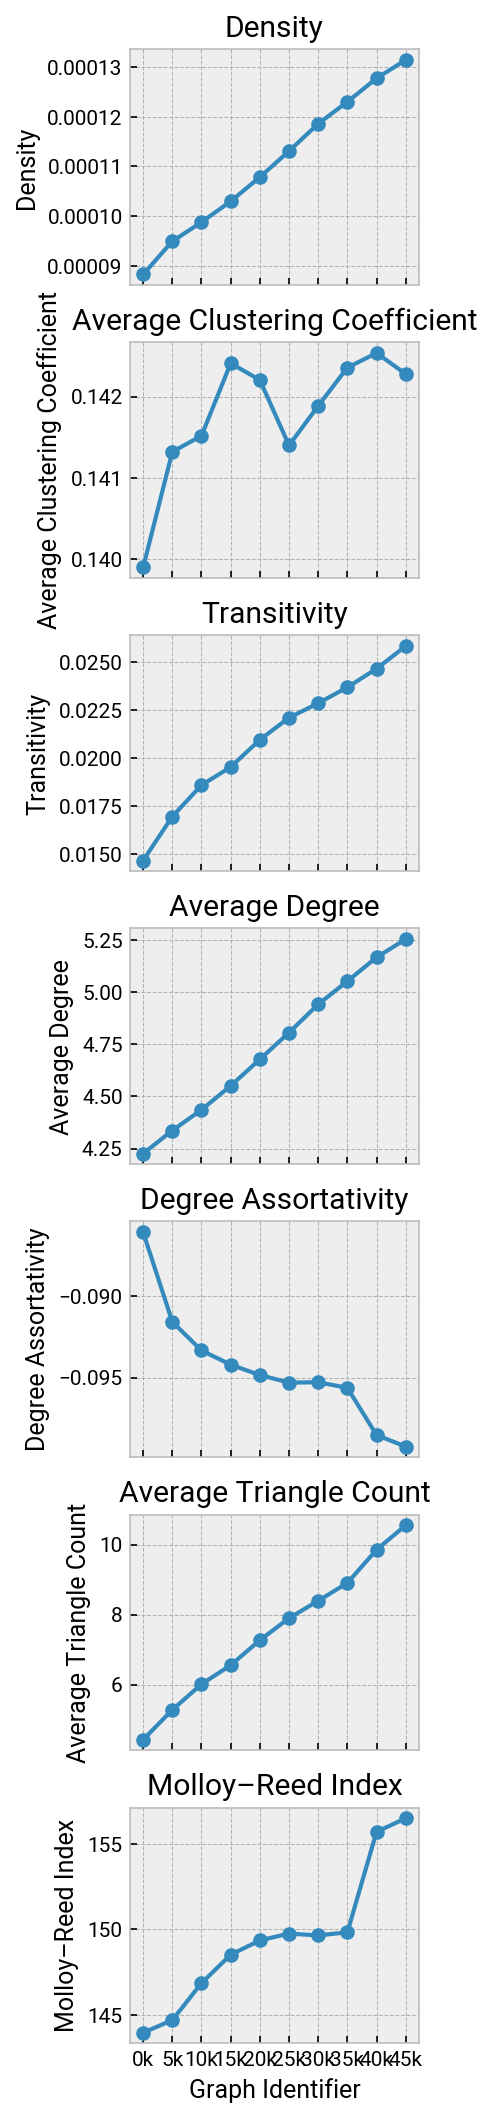

In [51]:
# Plot invariants

with plt.style.context("bmh"):
    fig, axs = plt.subplots(
        len(INVARIANTS), 1, figsize=(3, 2 * len(INVARIANTS)), dpi=150, sharex=True
    )
    for ax, (invariant_key, invariant_info) in zip(axs, INVARIANTS.items()):
        ylabel = invariant_info["ylabel"]
        graph_ids = list(invariants_per_graph[invariant_key].keys())
        values = list(invariants_per_graph[invariant_key].values())
        ax.plot(graph_ids, values, marker="o")
        ax.set_ylabel(ylabel)
        ax.set_title(f"{ylabel}")
        ax.grid(True)
    plt.tight_layout()
    ax.set_xlabel("Graph Identifier")
    refig.savefig("contactome_invariants_per_graph.svg")
    plt.show()

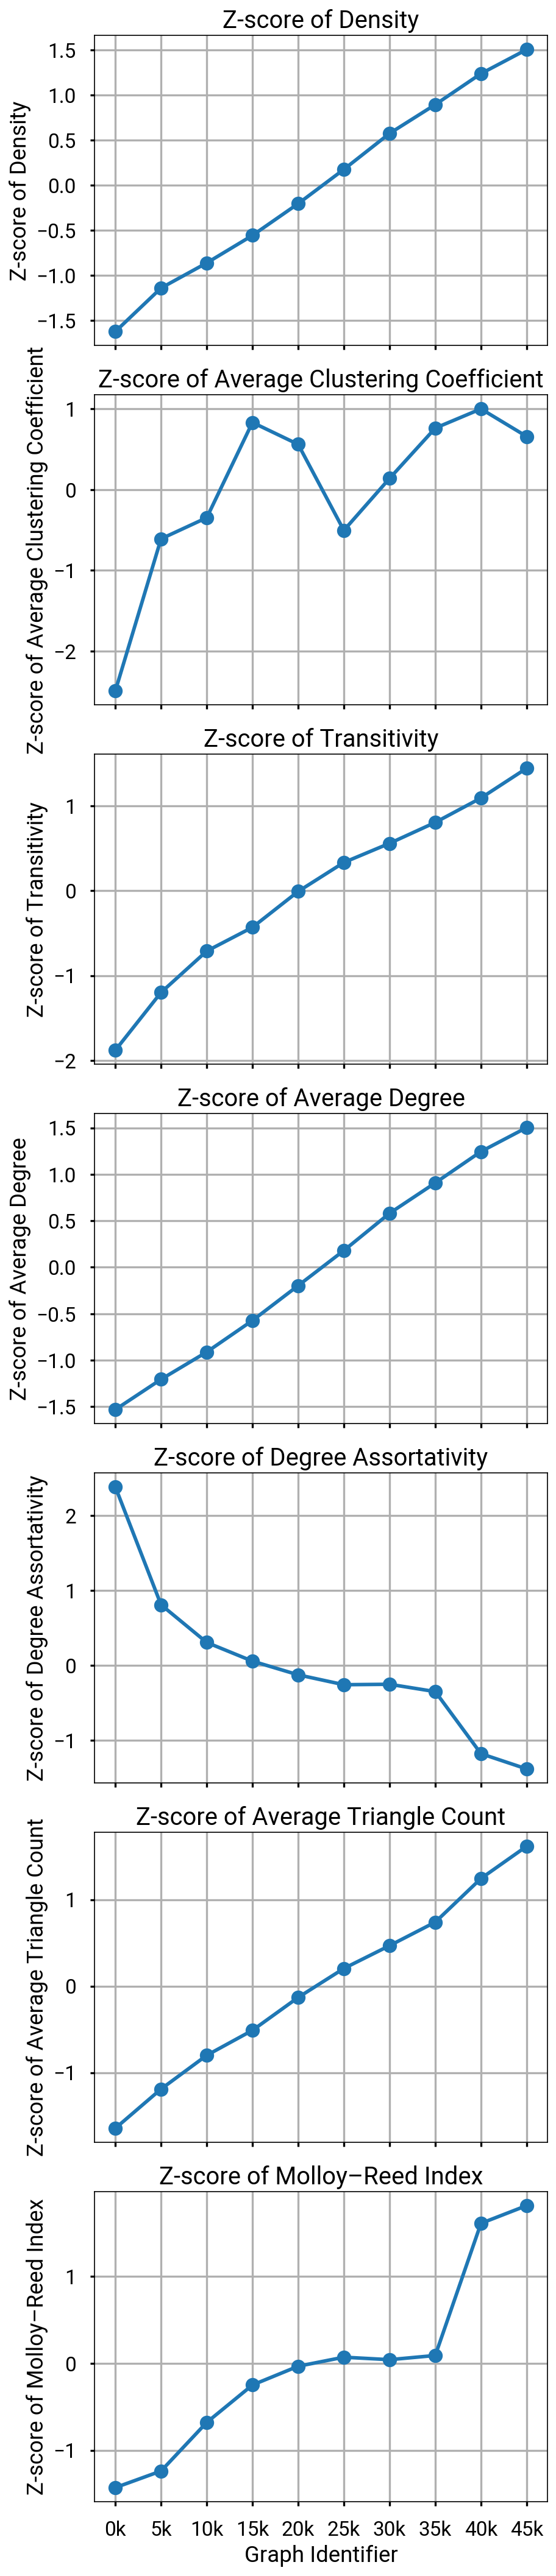

In [52]:
# Plot zscores of invariants

with plt.style.context("seaborn-v0_8-poster"):
    fig, axs = plt.subplots(len(INVARIANTS), 1, figsize=(6, 4 * len(INVARIANTS)), dpi=150, sharex=True)
    for ax, (invariant_key, invariant_info) in zip(axs, INVARIANTS.items()):
        ylabel = invariant_info["ylabel"]
        graph_ids = list(invariants_per_graph[invariant_key].keys())
        values = np.array(list(invariants_per_graph[invariant_key].values()))
        zscores = (values - np.mean(values)) / np.std(values)
        ax.plot(graph_ids, zscores, marker='o')
        ax.set_ylabel(f"Z-score of {ylabel}")
        ax.set_title(f"Z-score of {ylabel}")
        ax.grid(True)
    plt.tight_layout()
    ax.set_xlabel("Graph Identifier")
    refig.savefig("contactome_invariants_per_graph_zscores.svg")
    plt.show()

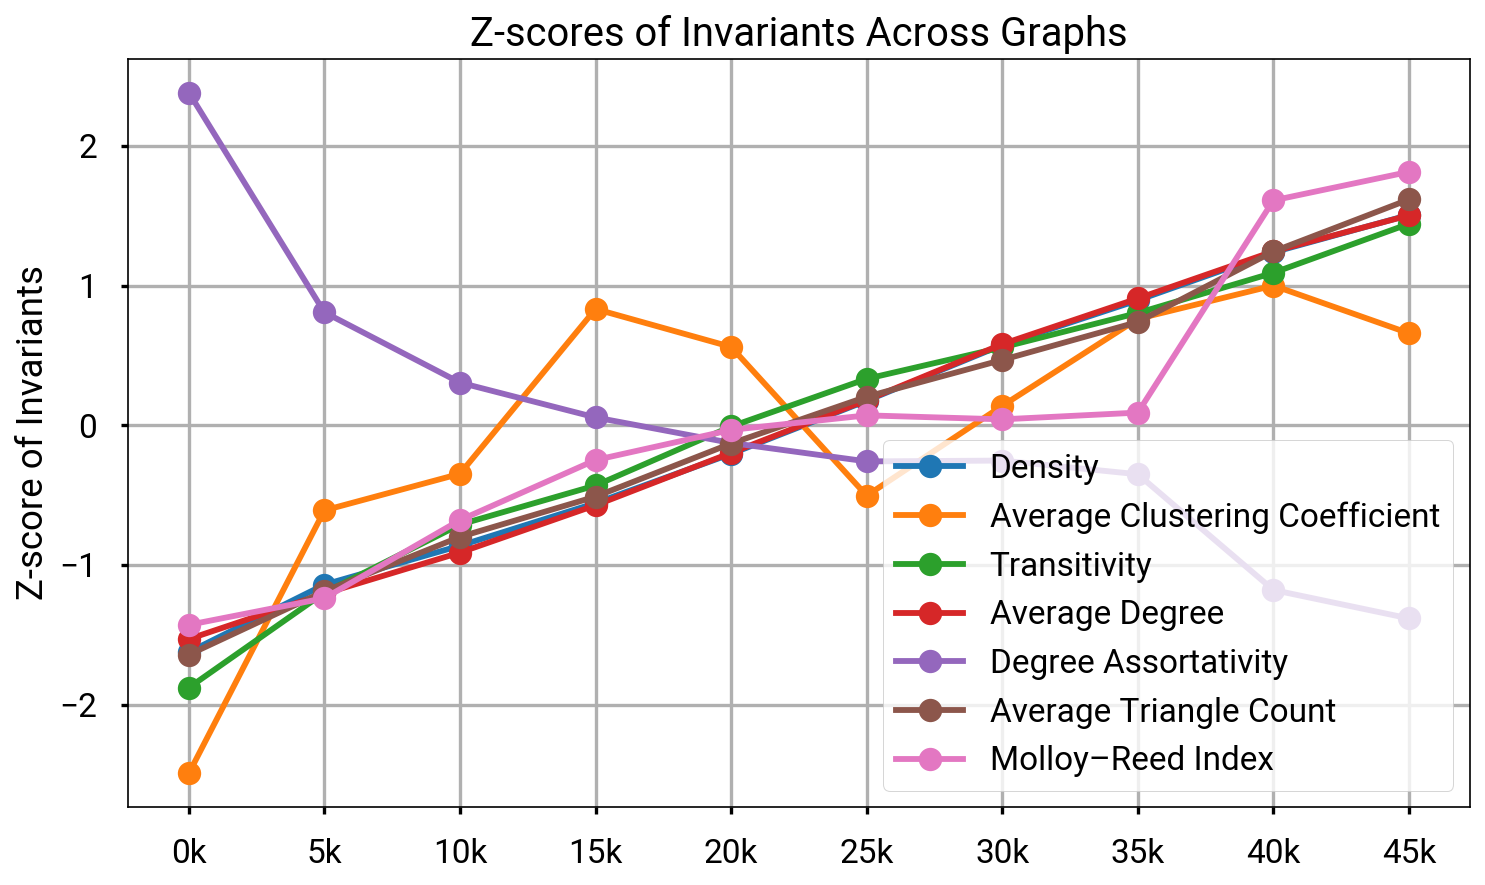

In [53]:
# Plot all zscores together
with plt.style.context("seaborn-v0_8-poster"):
    fig, ax = plt.subplots(figsize=(10, 6), dpi=150)
    for invariant_key, invariant_info in INVARIANTS.items():
        ylabel = invariant_info["ylabel"]
        graph_ids = list(invariants_per_graph[invariant_key].keys())
        values = np.array(list(invariants_per_graph[invariant_key].values()))
        zscores = (values - np.mean(values)) / np.std(values)
        ax.plot(graph_ids, zscores, marker='o', label=ylabel)
    ax.set_ylabel("Z-score of Invariants")
    ax.set_title("Z-scores of Invariants Across Graphs")
    ax.grid(True)
    ax.legend()
    plt.tight_layout()
    plt.show()

In [54]:
with open("contactome_invariants_per_graph.json", "w") as f:
    import json
    json.dump(invariants_per_graph, f, indent=2)